In [1]:
from PIL import Image
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
import pandas as pd
import os
import torch.nn as nn
import torch
from torchsummary import summary


folder_path = 'chest-xrays'

def proc(imnumb, use_mask=False):
    im = Image.open(f"{folder_path}/images/{imnumb}.png").convert('L')
    imm = Image.open(f"{folder_path}/mask/{imnumb}.png").convert('L')
    im = im.resize((512,512))
    #resize mask to match image; NEAREST keeps mask binary instead of blurring edges
    imm = imm.resize((512,512), Image.NEAREST)
    img_array = np.array(im)/255.0
    img_array = img_array.astype(np.float32)

    if use_mask:
        imm_array = np.array(imm)/255.0
        masked_array = img_array * imm_array
        img_array = masked_array.astype(np.float32)
    return img_array
    #masked_image = Image.fromarray(masked_array)
    #masked_image.save(f"{folder_path}/masked/{imnumb}.png")



In [2]:
#metadata loading 
images=[]
labels=[]
metadata = pd.read_csv("chest-xrays/MetaData.csv")

#print(metadata.head())

for idx, rows in metadata.iterrows():
    images.append(proc(rows['id']))
    labels.append(rows["ptb"])
    print(idx)
    

x_images = np.array(images)
y = np.array(labels)

#we can also include additional axis such as age,sex etc do this by adding a new axis to the x array which can include age numerically or sex as 0/1(consistency) 


0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
184
185
186
187
188
189
190
191
192
193
194
195
196
197
198
199
200
201
202
203
204
205
206
207
208
209
210
211
212
213
214
215
216
217
218
219
220
221
222
223
224
225
226
227
228
229
230
231
232
233
234
235
236
237
238
239
240
241
242
243
244
245
246
247
248
249
250
251
252
253
254
255
256
257
258
259
260
261
262
263
264
265
266
267
268
269
270
271
272
273
274
275
276
27

(704, 512, 512)
(704,)
[0 0 0 1 1 0 1 0 1 1 1 0 0 1 0 0 1 1 1 0 1 1 0 1 0 0 1 1 0 1 0 1 0 1 1 1 1
 1 1 0 0 0 0 0 1 0 1 1 0 1 0 0 0 1 1 1 1 1 1 1 1 0 0 0 1 0 0 0 0 0 0 1 0 1
 1 1 0 0 0 0 1 0 1 1 0 1 0 0 1 1 1 1 1 1 1 0 0 0 0 1 0 1 1 0 1 0 0 0 1 0 0
 0 0 0 1 1 0 0 1 0 0 0 1 1 0 0 0 1 1 1 1 1 0 1 0 0 0 0 0 1 1 1 0 1 0 0 1 0
 0 0 1 0 0 1 1 1 0 1 1 1 0 0 0 0 0 0 1 1 1 1 1 0 0 1 0 1 1 0 1 1 0 0 0 1 1
 1 1 0 0 1 0 1 1 0 0 1 1 0 1 1 0 1 1 1 1 0 1 1 1 1 0 1 1 0 1 0 0 1 1 0 0 1
 1 0 1 0 0 1 1 0 0 1 1 0 1 0 1 1 1 0 0 0 0 1 0 0 1 0 1 1 0 1 0 0 1 1 0 0 1
 0 1 0 0 0 0 0 1 1 0 1 0 1 1 0 1 0 1 0 0 1 1 1 1 0 1 1 0 1 0 0 0 0 1 0 0 0
 1 0 0 0 0 0 1 0 1 1 1 0 1 0 1 0 1 0 1 1 0 0 0 0 1 0 0 0 0 1 0 1 0 1 0 1 0
 0 0 0 1 0 0 0 0 0 1 0 0 1 1 0 1 1 0 0 0 0 1 0 1 1 0 1 0 0 0 1 0 1 1 1 0 1
 0 0 0 0 1 1 1 1 0 1 0 1 1 1 1 0 0 0 0 0 0 0 1 1 1 1 0 0 0 0 0 0 1 1 0 1 1
 0 1 1 1 0 0 1 1 1 1 1 0 1 0 1 1 0 0 0 0 1 0 0 0 0 0 0 0 1 1 1 0 0 0 1 0 1
 1 0 1 1 1 1 0 0 0 1 0 1 0 1 1 1 0 0 1 1 0 1 1 0 0 1 1 1 1 1 0 1 0 0 1 1 1
 1

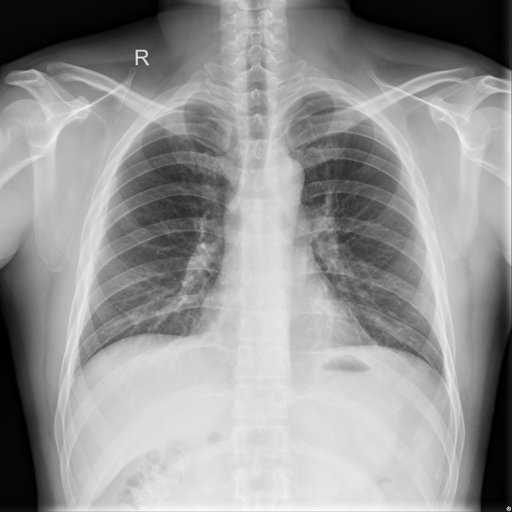

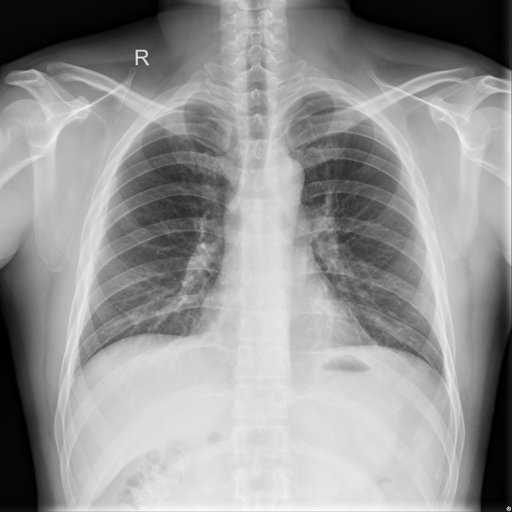

In [3]:
print(x_images.shape)
print(y.shape)
print(y)
((Image.fromarray(x_images[0]*255.0))).show()
a= Image.open(f"{folder_path}/images/{1000}.png").convert('L')
a.resize((512,512)).show()

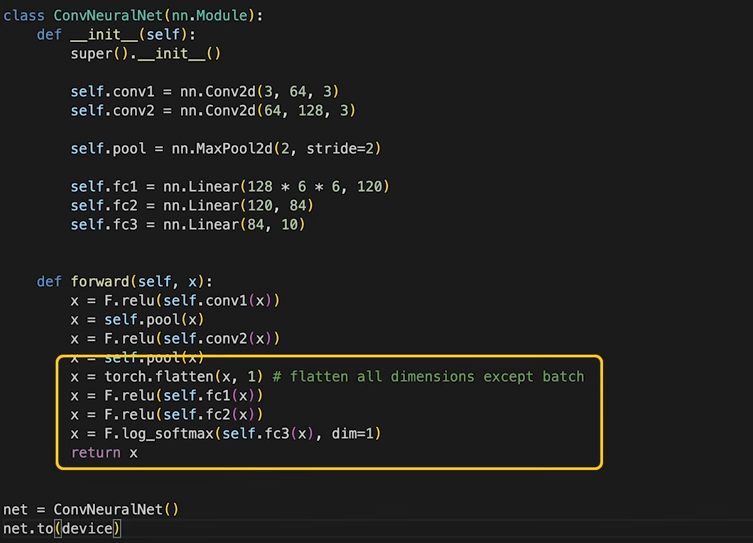

In [42]:
#spliting the data into training and testing
X_train, X_test, y_train, y_test = train_test_split(x_images, y, test_size=0.2, random_state=65)

class ConvNeuralNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(1,64,3)
        self.conv2 = nn.Conv2d(64,128,3)

        self.pool = nn.MaxPool2d(16, stride=16)

        self.fc1 = nn.Linear(128, 120)
        self.fc2 = nn.Linear(120,84)
        self.fc3 = nn.Linear(84,2)#final layer requires 2 classes since problem is +/- for TB

    def forward(self, x):
        x = nn.functional.relu(self.conv1(x))
        x = self.pool(x)
        x = nn.functional.relu(self.conv2(x))
        x = self.pool(x)
        x = torch.flatten(x,1)
        x = nn.functional.relu(self.fc1(x))
        x = nn.functional.relu(self.fc2(x))
        x = nn.functional.log_softmax(self.fc3(x),dim=1)
        return x
    
net = ConvNeuralNet()
net.to(torch.device('cuda'))



        
        


ConvNeuralNet(
  (conv1): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1))
  (conv2): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1))
  (pool): MaxPool2d(kernel_size=16, stride=16, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=128, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=2, bias=True)
)

In [43]:

#pytorch setup
device = torch.device('cuda')
print("a") if torch.cuda.is_available() else print("b")
#conv2d args = input size, output size and kernel size 


a


In [44]:
#summary(net,(1,512,512))

In [45]:
print(X_train.shape)

(563, 512, 512)


In [46]:
#Training
loss_function = nn.NLLLoss()
optimizer = torch.optim.Adam(net.parameters(), lr=0.001)

epochs = 10
for epoch in range(epochs):
    running_loss = 0.0
    for i in range(len(X_train)):
        input = torch.tensor(X_train[i]).unsqueeze(0).unsqueeze(0).to(device)
        label = torch.tensor([y_train[i]]).to(device)

        optimizer.zero_grad()
        outputs = net(input)
        loss = loss_function(outputs, label)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        if i % 2000 == 1999:
            print(f'{epoch+1}/{epochs}, {i+1:5d}] loss: {running_loss/2000:.3f}')
            running_loss = 0.0
print("Finished Training")


Finished Training


In [47]:
from sklearn.metrics import roc_auc_score, confusion_matrix

net.eval()  # Set the model to evaluation mode
all_outputs = []
all_labels = []

with torch.no_grad():
    for i in range(len(X_test)):
        input = torch.tensor(X_test[i]).unsqueeze(0).unsqueeze(0).to(device)
        label = torch.tensor([y_test[i]]).to(device)
        outputs = net(input)
        _, predicted = torch.max(outputs.data, 1)
        all_outputs.append(predicted.cpu().numpy())
        all_labels.append(label.cpu().numpy())

# Flatten the lists
all_outputs = np.concatenate(all_outputs)
all_labels = np.concatenate(all_labels)

# Calculate AUROC
auroc = roc_auc_score(all_labels, all_outputs)
print(f'AUROC: {auroc:.4f}')
# Compute confusion matrix
tn, fp, fn, tp = confusion_matrix(all_labels, all_outputs).ravel()

# Calculate sensitivity (recall or true positive rate)
sensitivity = tp / (tp + fn)
print(f'Sensitivity: {sensitivity:.4f}')

# Calculate specificity (true negative rate)
specificity = tn / (tn + fp)
print(f'Specificity: {specificity:.4f}')

AUROC: 0.7938
Sensitivity: 0.7681
Specificity: 0.8194


In [48]:
# Evaluate the model on the test set
from torchmetrics.classification import BinaryAUROC
net.eval()
auroc = BinaryAUROC().to(device)
correct = 0
total = 0
with torch.no_grad():
    for i in range(len(X_test)):
        input = torch.tensor(X_test[i]).unsqueeze(0).unsqueeze(0).to(device)
        label = torch.tensor([y_test[i]]).to(device)
        outputs = net(input)
        _, predicted = torch.max(outputs.data, 1)
        total += label.size(0)
        correct += (predicted == label).sum().item()

print(f'Accuracy of the network on the test images: {100 * correct / total}%')


Accuracy of the network on the test images: 79.43262411347517%
